# Курсовая работа № 4. Метод коллокации

Решаем стационарную задачу теплопроводности в стержне
$$-k u''(x)+q u(x)=f(x),\quad 0\le x\le1,\qquad u(0)=u_L,\quad u(1)=u_R.$$
Здесь $u$ — температура, $k>0$ — постоянная теплопроводность, $q\ge0$ — постоянный коэффициент теплоотдачи, $f$ — источник тепла. Температура и координата в примерах выражены в условных единицах.

Реализуем два базиса коллокации, сравним их с центральными конечными разностями и исследуем погрешность при изменении числа внутренних узлов. Код выполняется сверху вниз. Нужны NumPy и Matplotlib, графики и таблицы появляются внутри ноутбука.

Источники постановки и алгоритма — «Курсовые А-13-24.pdf», задача 4, стр. 7; «Курсовая_задача4_метод_коллокации_2.pages»; приложенные страницы §6 «Метод коллокации», включая стр. 233–234. Численные параметры и три тестовых решения выбраны для проверки реализации.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (10, 4), "font.size": 11})
K, Q = 2.0, 3.0
CHECK_X = np.linspace(0, 1, 4001)
METHODS = ["Многочлены", "Синусы", "Конечные разности"]

Matplotlib is building the font cache; this may take a moment.


## Построение тестовых задач

Задаём точное решение $u_*(x)$ и вычисляем $f(x)=-ku_*''(x)+qu_*(x)$, $u_L=u_*(0)$, $u_R=u_*(1)$. Тогда выбранная функция точно решает построенную краевую задачу.

| Тест | $u_*(x)$ | $u_*''(x)$ |
|---|---|---|
| Полином | $20+10x+8x(1-x)$ | $-16$ |
| Синус | $20+10x+8\sin(\pi x)$ | $-8\pi^2\sin(\pi x)$ |
| Экспонента | $20+10x+4[e^x-1-(e-1)x]$ | $4e^x$ |

Во всех тестах концы поддерживаются при температурах 20 и 30. Первый тест проверяет точное воспроизведение полинома, второй — воспроизведение синусной составляющей, третий позволяет сравнить сходимость на функции, которая не входит целиком в конечный базис.

In [2]:
def exact(x, test):
    x = np.asarray(x)
    if test == "Полином":
        return 20 + 10*x + 8*x*(1-x)
    if test == "Синус":
        return 20 + 10*x + 8*np.sin(np.pi*x)
    if test == "Экспонента":
        return 20 + 10*x + 4*(np.expm1(x) - np.expm1(1)*x)
    raise ValueError("Неизвестный тест")


def second_derivative(x, test):
    x = np.asarray(x)
    if test == "Полином":
        return np.full_like(x, -16.0, dtype=float)
    if test == "Синус":
        return -8*np.pi**2*np.sin(np.pi*x)
    if test == "Экспонента":
        return 4*np.exp(x)
    raise ValueError("Неизвестный тест")


def source(x, test, k=K, q=Q):
    return -k*second_derivative(x, test) + q*exact(x, test)


TESTS = ["Полином", "Синус", "Экспонента"]

## Базис и краевые условия

Возьмём $\phi_0(x)=u_L+(u_R-u_L)x$. Эта функция удовлетворяет граничным условиям, а $\phi_0''=0$. Ищем
$$u_n(x)=\phi_0(x)+\sum_{j=1}^n c_j\phi_j(x).$$

Для алгебраического базиса из приложенного описания
$$\phi_j=x^j(1-x)=x^j-x^{j+1},\qquad
\phi_j''=j(j-1)x^{j-2}-j(j+1)x^{j-1}.$$
При $j=1$ вычисляем отдельно $\phi_1''=-2$, чтобы не вычислять отрицательную степень в нуле.

Для тригонометрического базиса
$$\phi_j=\sin(j\pi x),\qquad \phi_j''=-(j\pi)^2\sin(j\pi x).$$
Сумма синусных функций образует требуемое тригонометрическое приближение. Все $\phi_j$ обращаются в нуль на обоих концах. Поэтому краевые условия выполнены для любых коэффициентов $c_j$.

In [3]:
def basis(x, n, kind):
    x = np.atleast_1d(x).astype(float)
    phi = np.empty((len(x), n))
    d2phi = np.empty_like(phi)
    for j in range(1, n + 1):
        if kind == "Многочлены":
            phi[:, j-1] = x**j * (1-x)
            if j == 1:
                d2phi[:, j-1] = -2
            else:
                d2phi[:, j-1] = j*(j-1)*x**(j-2) - j*(j+1)*x**(j-1)
        elif kind == "Синусы":
            phi[:, j-1] = np.sin(j*np.pi*x)
            d2phi[:, j-1] = -(j*np.pi)**2 * phi[:, j-1]
        else:
            raise ValueError("Неизвестный базис")
    return phi, d2phi

## Система коллокации

Подставляем приближение в оператор $L[u]=-ku''+qu$. Невязка равна
$$R(x)=q\phi_0(x)-f(x)+\sum_{j=1}^n c_j[-k\phi_j''(x)+q\phi_j(x)].$$
В $n$ внутренних узлах $x_i=i/(n+1)$ потребуем $R(x_i)=0$. Получаем СЛАУ
$$Ac=b,\qquad A_{ij}=-k\phi_j''(x_i)+q\phi_j(x_i),\qquad b_i=f(x_i)-q\phi_0(x_i).$$
Строка соответствует узлу, столбец — базисной функции. Решаем плотную систему через `np.linalg.solve`. Невязку дополнительно проверим между узлами. Большое число обусловленности матрицы означает чувствительность коэффициентов к округлению.

In [4]:
def collocation(n, kind, f, left, right, x_eval, k=K, q=Q):
    nodes = np.arange(1, n+1) / (n+1)
    phi, d2phi = basis(nodes, n, kind)
    matrix = -k*d2phi + q*phi
    lift = left + (right-left)*nodes
    rhs = f(nodes) - q*lift
    coefficients = np.linalg.solve(matrix, rhs)

    phi_eval, d2_eval = basis(x_eval, n, kind)
    solution = left + (right-left)*x_eval + phi_eval @ coefficients
    residual = -k*(d2_eval @ coefficients) + q*solution - f(x_eval)
    node_residual = np.max(np.abs(matrix @ coefficients - rhs))
    return solution, coefficients, residual, node_residual, np.linalg.cond(matrix)

## Метод конечных разностей

Для сравнения берём те же $n$ внутренних узлов, $h=1/(n+1)$. Центральная формула даёт
$$u''(x_i)\approx\frac{u_{i-1}-2u_i+u_{i+1}}{h^2},$$
$$-\frac{k}{h^2}u_{i-1}+\left(\frac{2k}{h^2}+q\right)u_i-\frac{k}{h^2}u_{i+1}=f(x_i).$$
Известные граничные значения переносим в правую часть: к первой строке прибавляем $ku_L/h^2$, к последней — $ku_R/h^2$. Схема имеет второй порядок точности для гладкого решения. Для небольших систем используем `np.linalg.solve`, как допускает описание работы.

In [5]:
def finite_difference(n, f, left, right, k=K, q=Q):
    grid = np.linspace(0, 1, n+2)
    h = 1/(n+1)
    diagonal = 2*k/h**2 + q
    off_diagonal = -k/h**2
    matrix = np.diag(np.full(n, diagonal))
    matrix += np.diag(np.full(n-1, off_diagonal), 1)
    matrix += np.diag(np.full(n-1, off_diagonal), -1)
    rhs = np.array(f(grid[1:-1]), dtype=float, copy=True)
    rhs[0] += k*left/h**2
    rhs[-1] += k*right/h**2
    solution = np.r_[left, np.linalg.solve(matrix, rhs), right]
    return grid, solution

## Проверка реализации

Проверяем граничные условия и невязку в узлах. Полином должен воспроизводиться первым алгебраическим базисом, а синусный тест — первым синусом. Для центральной разности вторая производная квадратичного полинома точна. Отдельно проверяем случай одного внутреннего узла, когда оба граничных слагаемых попадают в одну строку.

In [6]:
for kind, test in [("Многочлены", "Полином"), ("Синусы", "Синус")]:
    f = lambda x: source(x, test)
    solution, coefficients, residual, node_error, condition = collocation(
        1, kind, f, 20, 30, CHECK_X)
    assert np.max(abs(solution-exact(CHECK_X, test))) < 1e-10
    assert np.max(abs(solution[[0, -1]] - [20, 30])) < 1e-12
    assert node_error < 1e-10

for n in [1, 8, 32]:
    grid, solution = finite_difference(n, lambda x: source(x, "Полином"), 20, 30)
    assert np.max(abs(solution-exact(grid, "Полином"))) < 1e-10
print("Проверки базисов, граничных условий и разностной схемы пройдены.")

Проверки базисов, граничных условий и разностной схемы пройдены.


## Сравнение на трёх тестах

Используем $n=10$ неизвестных для каждого метода. В таблице $E_{узлы}$ измеряется в одинаковых внутренних узлах, $E_{контр}$ — на общей контрольной сетке из 4001 точки. Для МКР между узлами используется линейная интерполяция, поэтому её ошибка на контрольной сетке включает ошибку интерполяции. Эти две оценки выводим отдельно. Максимумы на конечной сетке служат численной оценкой равномерной ошибки.

Для отображения на логарифмической шкале значения ошибок меньше 10⁻¹⁵ заменены на 10⁻¹⁵ только на рисунках. Таблицы содержат вычисленные значения без этого ограничения.

Тест           Метод                      E_узлы      E_контр
Полином        Многочлены              0.000e+00    3.553e-15
Полином        Синусы                  1.123e-02    1.242e-02
Полином        Конечные разности       1.066e-14    1.653e-02
Синус          Многочлены              1.266e-07    1.311e-07
Синус          Синусы                  0.000e+00    0.000e+00
Синус          Конечные разности       4.687e-02    4.671e-02
Экспонента     Многочлены              1.243e-13    1.315e-13
Экспонента     Синусы                  7.292e-03    8.205e-03
Экспонента     Конечные разности       5.046e-04    1.083e-02


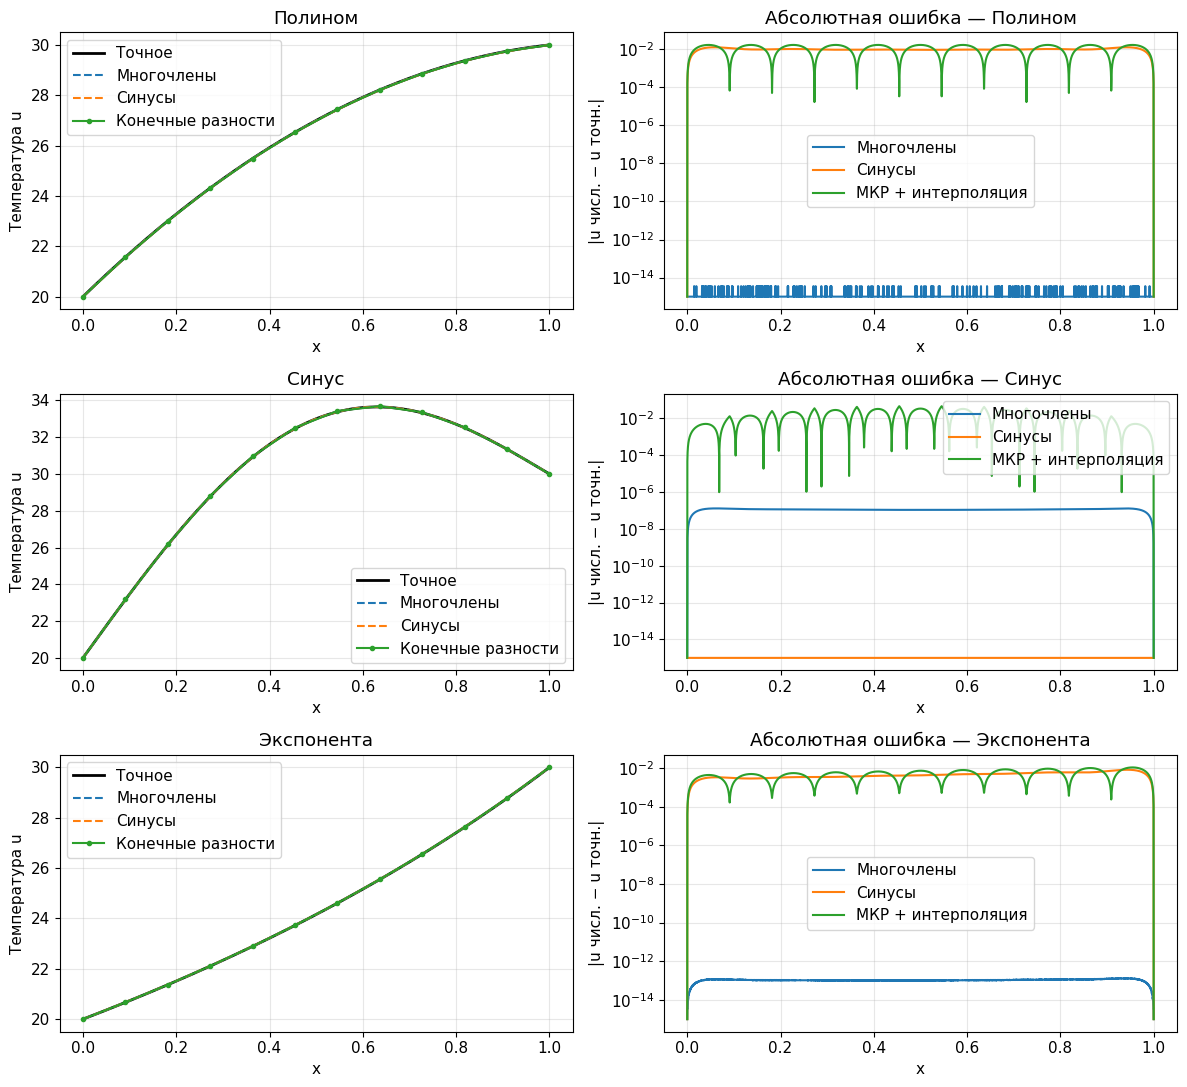

In [7]:
n = 10
fig, axes = plt.subplots(3, 2, figsize=(12, 11))
print(f"{'Тест':14} {'Метод':20} {'E_узлы':>12} {'E_контр':>12}")
for row, test in enumerate(TESTS):
    f = lambda x: source(x, test)
    truth = exact(CHECK_X, test)
    nodes = np.arange(1, n+1)/(n+1)
    axes[row, 0].plot(CHECK_X, truth, 'k', linewidth=2, label='Точное')
    for kind in METHODS[:2]:
        solution, c, residual, rnodes, condition = collocation(n, kind, f, 20, 30, CHECK_X)
        phi, _ = basis(nodes, n, kind)
        node_solution = 20 + 10*nodes + phi @ c
        en = np.max(abs(node_solution-exact(nodes, test)))
        ec = np.max(abs(solution-truth))
        print(f"{test:14} {kind:20} {en:12.3e} {ec:12.3e}")
        axes[row, 0].plot(CHECK_X, solution, '--', label=kind)
        axes[row, 1].semilogy(CHECK_X, np.maximum(abs(solution-truth), 1e-15), label=kind)
    grid, discrete = finite_difference(n, f, 20, 30)
    interpolated = np.interp(CHECK_X, grid, discrete)
    en = np.max(abs(discrete-exact(grid, test)))
    ec = np.max(abs(interpolated-truth))
    print(f"{test:14} {'Конечные разности':20} {en:12.3e} {ec:12.3e}")
    axes[row, 0].plot(grid, discrete, 'o-', markersize=3, label='Конечные разности')
    axes[row, 1].semilogy(CHECK_X, np.maximum(abs(interpolated-truth), 1e-15), label='МКР + интерполяция')
    axes[row, 0].set(title=test, xlabel='x', ylabel='Температура u')
    axes[row, 1].set(title=f'Абсолютная ошибка — {test}', xlabel='x', ylabel='|u числ. − u точн.|')
for ax in axes.flat:
    ax.grid(alpha=0.3)
    ax.legend()
fig.tight_layout()
plt.show()

## Погрешность в зависимости от количества узлов

Для экспоненциального теста меняем $n$ — число внутренних узлов и неизвестных коэффициентов. Полное число узлов с концами равно $n+2$. Алгебраический базис из степеней становится плохо обусловленным при росте $n$, поэтому вместе с ошибкой отслеживаем $\operatorname{cond}(A)$. Для синусного базиса остаток после вычитания линейной функции равен нулю на концах, но его вторая производная на концах ненулевая. Поэтому здесь не ожидаем точного воспроизведения конечной суммой синусов.

Показываем и ошибку в узлах, и ошибку на общей контрольной сетке. Добавление узлов не гарантирует монотонного уменьшения ошибки при округлении.

  n Метод                      E_узлы      E_контр      cond(A)
  2 Многочлены              6.279e-03    7.670e-03    2.867e+00
  2 Синусы                  7.564e-02    9.918e-02    3.604e+00
  2 Конечные разности       6.279e-03    1.313e-01            —
  4 Многочлены              3.040e-05    3.358e-05    5.598e+01
  4 Синусы                  3.143e-02    3.757e-02    1.402e+01
  4 Конечные разности       2.403e-03    5.011e-02            —
  6 Многочлены              7.599e-08    8.105e-08    1.841e+03
  6 Синусы                  1.704e-02    1.970e-02    3.138e+01
  6 Конечные разности       1.241e-03    2.619e-02            —
  8 Многочлены              1.171e-10    1.228e-10    7.462e+04
  8 Синусы                  1.066e-02    1.212e-02    5.569e+01
  8 Конечные разности       7.531e-04    1.605e-02            —
 10 Многочлены              1.243e-13    1.315e-13    3.373e+06
 10 Синусы                  7.292e-03    8.205e-03    8.694e+01
 10 Конечные разности       5.046e-04   

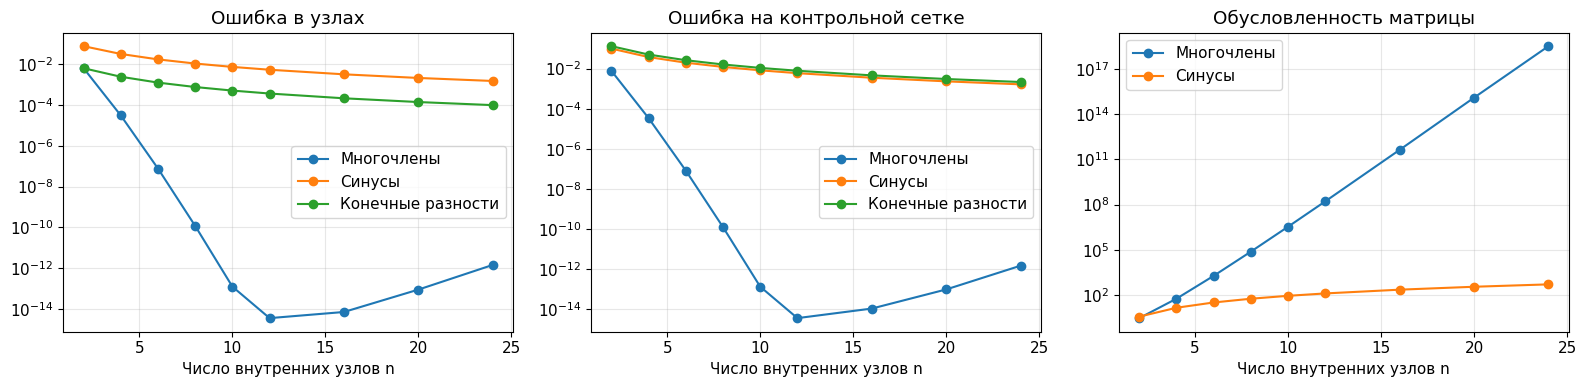

Наблюдаемые порядки МКР: [1.9993 1.9985 2.    ]


In [8]:
counts = [2, 4, 6, 8, 10, 12, 16, 20, 24]
test = "Экспонента"
f = lambda x: source(x, test)
errors_nodes = {method: [] for method in METHODS}
errors_control = {method: [] for method in METHODS}
conditions = {kind: [] for kind in METHODS[:2]}
print(f"{'n':>3} {'Метод':20} {'E_узлы':>12} {'E_контр':>12} {'cond(A)':>12}")
for n in counts:
    nodes = np.arange(1, n+1)/(n+1)
    for kind in METHODS[:2]:
        solution, c, residual, rnodes, condition = collocation(n, kind, f, 20, 30, CHECK_X)
        phi, _ = basis(nodes, n, kind)
        en = np.max(abs(20+10*nodes+phi@c-exact(nodes, test)))
        ec = np.max(abs(solution-exact(CHECK_X, test)))
        errors_nodes[kind].append(en)
        errors_control[kind].append(ec)
        conditions[kind].append(condition)
        print(f"{n:3} {kind:20} {en:12.3e} {ec:12.3e} {condition:12.3e}")
    grid, solution = finite_difference(n, f, 20, 30)
    en = np.max(abs(solution-exact(grid, test)))
    ec = np.max(abs(np.interp(CHECK_X, grid, solution)-exact(CHECK_X, test)))
    errors_nodes[METHODS[2]].append(en)
    errors_control[METHODS[2]].append(ec)
    print(f"{n:3} {METHODS[2]:20} {en:12.3e} {ec:12.3e} {'—':>12}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for method in METHODS:
    axes[0].semilogy(counts, np.maximum(errors_nodes[method], 1e-15), 'o-', label=method)
    axes[1].semilogy(counts, np.maximum(errors_control[method], 1e-15), 'o-', label=method)
for kind in METHODS[:2]:
    axes[2].semilogy(counts, conditions[kind], 'o-', label=kind)
for ax, title in zip(axes, ['Ошибка в узлах', 'Ошибка на контрольной сетке', 'Обусловленность матрицы']):
    ax.set(title=title, xlabel='Число внутренних узлов n')
    ax.grid(alpha=0.3)
    ax.legend()
fig.tight_layout()
plt.show()

# Для оценки порядка МКР шаги уменьшаются ровно вдвое.
fd_errors = []
for n in [15, 31, 63, 127]:
    grid, solution = finite_difference(n, f, 20, 30)
    fd_errors.append(np.max(abs(solution-exact(grid, test))))
orders = np.log2(np.array(fd_errors[:-1])/fd_errors[1:])
print("Наблюдаемые порядки МКР:", np.round(orders, 4))
assert np.all(abs(orders-2) < 0.05)

## Температура стержня и невязка между узлами

Для синусного теста источник $f=(2\pi^2+3)8\sin(\pi x)+3(20+10x)$ нагревает внутреннюю часть стержня. Температура внутри может превышать температуры обоих концов. Покажем температурный профиль, термограмму тонкого стержня и невязку $R=-ku_n''+qu_n-f$. Невязка и ошибка решения измеряют разные величины. Нулевые значения невязки в точках коллокации задаются СЛАУ, между ними она может быть ненулевой.

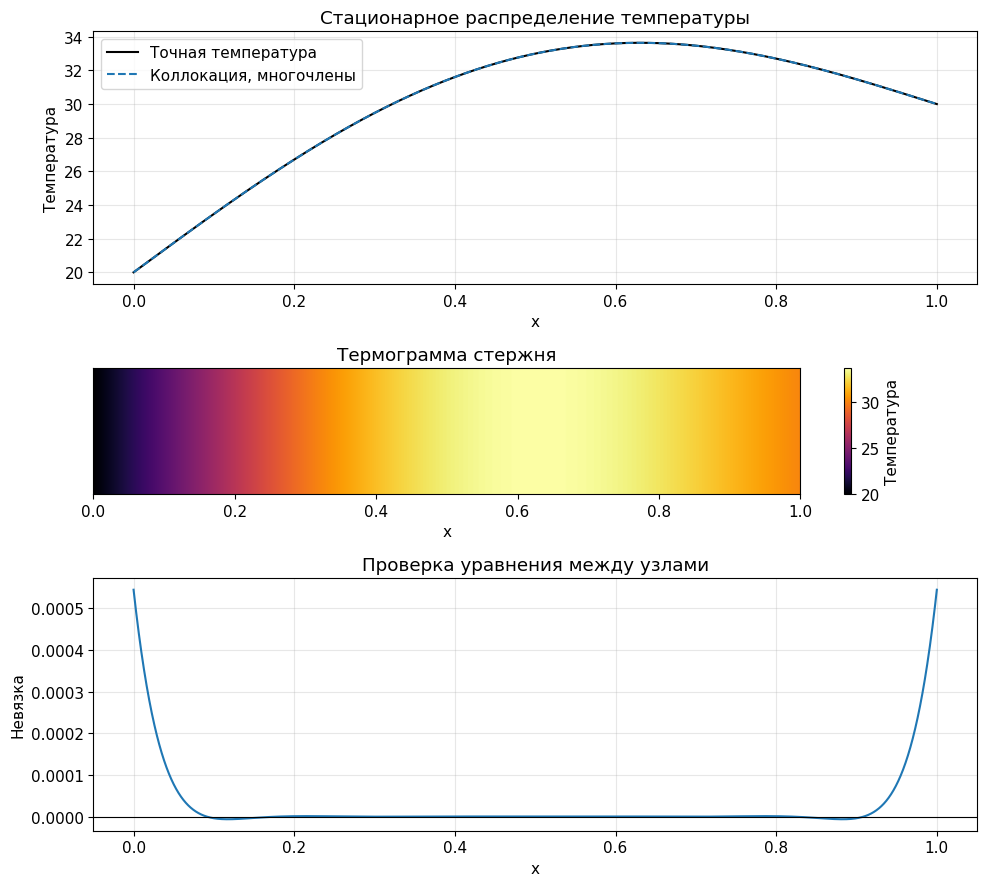

Максимальная невязка в узлах: 7.105e-14
Максимальная невязка на контрольной сетке: 5.449e-04
Максимальная температура: 33.642039


In [9]:
test, n = "Синус", 10
f = lambda x: source(x, test)
solution, c, residual, rnodes, condition = collocation(n, "Многочлены", f, 20, 30, CHECK_X)
fig, axes = plt.subplots(3, 1, figsize=(10, 9), gridspec_kw={'height_ratios': [2, 1, 2]})
axes[0].plot(CHECK_X, exact(CHECK_X, test), 'k', label='Точная температура')
axes[0].plot(CHECK_X, solution, '--', label='Коллокация, многочлены')
axes[0].set(xlabel='x', ylabel='Температура', title='Стационарное распределение температуры')
axes[0].legend()
axes[0].grid(alpha=0.3)
heat = axes[1].imshow(np.tile(solution, (12, 1)), extent=[0, 1, 0, 0.1],
                     origin='lower', aspect='auto', cmap='inferno')
axes[1].set(xlabel='x', title='Термограмма стержня', yticks=[])
fig.colorbar(heat, ax=axes[1], label='Температура')
axes[2].plot(CHECK_X, residual, label='R(x)')
axes[2].axhline(0, color='black', linewidth=0.8)
axes[2].set(xlabel='x', ylabel='Невязка', title='Проверка уравнения между узлами')
axes[2].grid(alpha=0.3)
fig.tight_layout()
plt.show()
print(f"Максимальная невязка в узлах: {rnodes:.3e}")
print(f"Максимальная невязка на контрольной сетке: {np.max(abs(residual)):.3e}")
print(f"Максимальная температура: {np.max(solution):.6f}")

## Выводы

Метод коллокации сводит краевую задачу к плотной СЛАУ относительно коэффициентов базисных функций. Выбор линейной функции для граничных значений и базиса, равного нулю на концах, обеспечивает краевые условия при любом числе членов.

Точность зависит от выбранного базиса и теста. Полиномиальный тест воспроизводится одним алгебраическим членом, синусный — одним тригонометрическим членом. Для экспоненциального теста результаты таблиц показывают сходимость и влияние округления при плохо обусловленном алгебраическом базисе. Малую невязку в узлах следует дополнять проверкой решения между узлами.

МКР даёт трёхдиагональную систему и второй порядок сходимости, который проверен последовательным делением шага пополам. На контрольной сетке его ошибка включает линейную интерполяцию. Сравнение с коллокацией выполнено при одинаковом числе неизвестных и с отдельной оценкой ошибки в общих узлах.

Для экспериментов можно менять K, Q и число узлов. В тестовых задачах источник пересчитывается из точного решения. Для самостоятельной физической задачи в функции collocation или finite_difference передайте свою функцию f и температуры концов.

В выполненном запуске при n=10 для экспоненциального теста ошибки в узлах составили примерно 1.24·10⁻¹³ для многочленов, 7.29·10⁻³ для синусов и 5.05·10⁻⁴ для МКР. Для многочленов ошибка на контрольной сетке снизилась до уровня округления при n=12, а при n=24 выросла примерно до 1.47·10⁻¹² при cond(A)≈3.3·10¹⁸. Это результат данного теста и данной арифметики, а не гарантия устойчивости большого степенного базиса. Наблюдаемые порядки МКР равны 1.9993, 1.9985 и 2.0000.